# Run analysis: `run-4_baseline-sel-feat-purged-5-fold-val-retrain`

Test-period analysis of a rolling-window training run. Compared against the baseline run `run-3_baseline-chrono-val-plus-retrain`.

Reads the run's `results_lgbm.json`, `predictions/` and `curves/`. Saves every
figure to `plots/analysis_*.png`. Generated by the `analyze-ts48-results`
skill; re-run top to bottom.

Sections:
1. Daily metrics: Pearson IC, Rank IC (Spearman), daily Kendall, Q5−Q1
2. Per-window summary: ICIR, Newey–West t, train/val/test R², cost
3. Plots: IC over time, cumulative IC, per-window metrics, R², quintiles,
   calibration
4. Finer grain: months and robust summaries
5. Ex-ante regimes
6. What changed vs the baseline: setup differences, automatic script diff,
   row and feature counts (only if a baseline is set)
7. Comparison with the baseline: paired daily differences on the same stocks
   and dates (only if a baseline is set)
8. Findings, summary and hypotheses (hypotheses only with a baseline)

**Ground rules** (from the baseline analysis, `claude/project-notes.md`):
- **Ranking and magnitude both matter.** The predictions feed a portfolio
  optimizer. Rank IC is the robust ranking measure (Pearson IC is inflated
  by fat-tailed labels); calibration slope, R² and RMSE judge magnitudes.
- **The label** is roughly a 5-day forward residual return. No further
  financial meaning is attached; values are in label units.
- **Significance uses Newey–West t.** Overlapping 5-day labels make daily
  ICs autocorrelated, so naive t-stats are ~1.7× too high.
- **Months are diagnostics.** ~20 days is only ~5 independent days, and
  months are never excluded from headline numbers.
- **Regimes use only information known at T.**
- **Comparisons are paired** on the same (Date, Code) rows.
- **The final reserved window** is evaluated only once, at the end of the
  project.


In [1]:
import json
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from matplotlib.patches import Patch
from scipy import stats

# The notebook lives in the run folder; VS Code runs it from there.
RUN_DIR = Path.cwd()
BASELINE_DIR = Path("/workspaces/TimeSeries48/runs/run-3_baseline-chrono-val-plus-retrain")  # Path to the baseline run folder, or None (set by the skill).
assert (RUN_DIR / "results_lgbm.json").exists(), f"Not a run folder: {RUN_DIR}"
COMPARE = BASELINE_DIR is not None and BASELINE_DIR.resolve() != RUN_DIR.resolve()
DATA_FILE = RUN_DIR.parents[1] / "data.parquet"
PLOTS_DIR = RUN_DIR / "plots"
PLOTS_DIR.mkdir(exist_ok=True)

# Fixed categorical order, never cycled: one colour per window (7th = final window).
WINDOW_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
SPLIT_COLORS = {"train": "#52514e", "val": "#6250d6", "test": "#e34948"}
MODEL_COLORS = {"baseline": "#8f8e88", "run": "#2a78d6"}
plt.rcParams.update({
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "lines.linewidth": 2,
    "legend.frameon": False,
})
warnings.filterwarnings("ignore", message=".*non-interactive.*")


def save(fig, name: str) -> None:
    """Save a figure to plots/analysis_<name>.png, then show it."""
    fig.savefig(PLOTS_DIR / f"analysis_{name}.png", dpi=120, bbox_inches="tight")
    plt.show()


def newey_west_t(x: np.ndarray, lags: int = 4) -> float:
    """t-statistic of mean(x) with a Newey–West (Bartlett-weighted) standard error."""
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    e = x - x.mean()
    n = len(x)
    var = e @ e / n
    for lag in range(1, min(lags, n - 1) + 1):
        var += 2 * (1 - lag / (lags + 1)) * (e[lag:] @ e[:-lag]) / n
    return float(x.mean() / np.sqrt(var / n))


def nw_ci(x: np.ndarray) -> float:
    """Half-width of a 95% confidence interval for mean(x), Newey–West (4 lags)."""
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    t = newey_west_t(x)
    return float(1.96 * abs(x.mean() / t)) if t else float("nan")


def find_files(run_dir: Path, kind: str, pattern: str) -> list[Path]:
    """Files in run_dir/<kind>/ (current layout) or run_dir/ (early runs' flat layout)."""
    sub = run_dir / kind
    files = sorted(sub.glob(pattern)) if sub.is_dir() else []
    return files or sorted(run_dir.glob(pattern))


def load_run(run_dir: Path) -> tuple[list[dict], pl.DataFrame, dict[int, dict]]:
    """Results, test predictions (with a 1-based `window` column) and learning curves."""
    results = json.loads((run_dir / "results_lgbm.json").read_text())
    start_to_window = {r["test_start"]: k + 1 for k, r in enumerate(results)}

    def window_of(path: Path) -> int:
        return start_to_window[re.search(r"_test_(\d{4}-\d{2}-\d{2})_", path.name)[1]]

    preds = pl.concat([
        pl.read_parquet(f).with_columns(pl.lit(window_of(f)).cast(pl.Int32).alias("window"))
        for f in find_files(run_dir, "predictions", "predictions_*.parquet")
    ]).sort(["window", "Date", "Code"])
    curves = {window_of(f): json.loads(f.read_text())
              for f in find_files(run_dir, "curves", "curves_*.json")}
    return results, preds, curves


def daily_metrics(preds: pl.DataFrame) -> tuple[pl.DataFrame, pl.DataFrame, pl.DataFrame]:
    """Per-date IC, Rank IC, Kendall and Q5−Q1; plus quintile means and preds with quintiles."""
    daily = (
        preds.group_by(["window", "Date"], maintain_order=True)
        .agg(
            pl.corr("Prediction", "label").alias("ic"),
            pl.corr("Prediction", "label", method="spearman").alias("rank_ic"),
            pl.len().alias("n"),
        )
        .sort(["window", "Date"])
    )
    kendall = [
        stats.kendalltau(d["Prediction"].to_numpy(), d["label"].to_numpy()).statistic
        for d in preds.sort(["window", "Date"]).partition_by(["window", "Date"], maintain_order=True)
    ]
    daily = daily.with_columns(pl.Series("kendall", kendall))
    key = ["window", "Date"]
    preds = preds.with_columns(
        ((pl.col("Prediction").rank("ordinal").over(key).cast(pl.Int64) - 1) * 5
         // pl.len().over(key) + 1).alias("quintile")
    )
    quint_daily = preds.group_by(["window", "Date", "quintile"]).agg(
        pl.col("label").mean().alias("label_mean")
    )
    spread = (
        quint_daily.pivot(on="quintile", index=["window", "Date"], values="label_mean")
        .select("window", "Date", (pl.col("5") - pl.col("1")).alias("q5_minus_q1"))
    )
    daily = daily.join(spread, on=["window", "Date"]).sort(["window", "Date"])
    return daily, quint_daily, preds


In [2]:
results, preds, curves = load_run(RUN_DIR)
n_windows = len(results)
assert preds["window"].n_unique() == n_windows, "predictions missing for some windows"
print(f"RUN {RUN_DIR.name}: {n_windows} windows, {preds.height:,} test rows, "
      f"{preds['Date'].n_unique()} test dates ({preds['Date'].min()} -> {preds['Date'].max()})")
if len(curves) != n_windows:
    print(f"  note: learning curves found for {len(curves)} of {n_windows} windows")

if COMPARE:
    b_results, b_preds, b_curves = load_run(BASELINE_DIR)
    print(f"BASELINE {BASELINE_DIR.name}: {len(b_results)} windows, {b_preds.height:,} rows, "
          f"{b_preds['Date'].min()} -> {b_preds['Date'].max()}")
    run_windows = {(r["test_start"], r["test_end"]) for r in results}
    base_windows = {(r["test_start"], r["test_end"]) for r in b_results}
    if run_windows != base_windows:
        print("  WARNING: test windows differ between run and baseline; "
              "the comparison uses only their common (Date, Code) rows.")


RUN run-4_baseline-sel-feat-purged-5-fold-val-retrain: 6 windows, 2,028,817 test rows, 720 test dates (2022-12-29 -> 2025-12-18)
BASELINE run-3_baseline-chrono-val-plus-retrain: 6 windows, 2,028,817 rows, 2022-12-29 -> 2025-12-18


## 1. Daily metrics

Every metric is computed **within each test date** (stocks vs stocks on the
same day), then summarised per window.

- **IC:** Pearson correlation of prediction and label. Uses magnitudes, so
  it is sensitive to extreme stocks.
- **Rank IC:** Spearman correlation, i.e. ordering only. The robust ranking
  metric (magnitudes are judged separately, by calibration and R²).
- **Kendall:** pairwise ordering agreement; numerically ≈ 0.68 × Rank IC.
- **Q5−Q1:** mean label of the top prediction quintile minus the bottom
  quintile, in label units (the label is roughly a 5-day forward residual
  return; no further financial meaning is attached). Gross, not a profit.


In [3]:
daily, quint_daily, preds = daily_metrics(preds)
daily.head()


window,Date,ic,rank_ic,n,kendall,q5_minus_q1
i32,date,f64,f64,u32,f64,f32
1,2022-12-29,0.07759,0.018128,2721,0.010402,0.002368
1,2022-12-30,0.060202,0.02163,2722,0.013865,0.001568
1,2023-01-03,0.117792,0.019353,2724,0.010626,0.002714
1,2023-01-04,0.073071,0.020018,2724,0.012001,0.00413
1,2023-01-05,0.020297,0.047827,2724,0.031274,0.002994


## 2. Per-window summary

- **ICIR** = mean(IC) / std(IC), unscaled, so it is comparable across windows.
  The training script's `ir` multiplies by √days and is really a naive
  t-statistic.
- **t (naive)** assumes independent days. **t (NW)** uses Newey–West standard
  errors with 4 lags, needed because the 5-day labels overlap. **IC ac1** is
  the lag-1 autocorrelation of daily IC.
- **train / val R²** at `best_iteration`, from the learning curves; **test
  R²** from the results. val ≫ test can mean the interleaved-validation leak
  (I-1) **or** a hard test period: check months (section 4) before blaming
  the leak.
- R² and calibration are meaningful only if predictions are in label units.
  They are not if the run trains on transformed labels (e.g. rank-Gauss).


In [4]:
def curve_at(c: dict | None, split: str, metric: str) -> float:
    """A learning-curve metric at best_iteration; NaN if it wasn't recorded."""
    if not c or not c.get("best_iteration"):
        return float("nan")
    values = c["curves"].get(split, {}).get(metric)
    best = c["best_iteration"]
    return values[best - 1] if values and best <= len(values) else float("nan")


rows = []
for w in range(1, n_windows + 1):
    d = daily.filter(pl.col("window") == w)
    ic = d["ic"].drop_nans().to_numpy()
    r = results[w - 1]
    rows.append({
        "window": w,
        "test": f"{r['test_start']} -> {r['test_end']}",
        "days": len(ic),
        "features": r.get("features"),
        "best_iter": r.get("best_iteration"),
        "IC": ic.mean(),
        "RankIC": d["rank_ic"].mean(),
        "Kendall(daily)": d["kendall"].mean(),
        "ICIR": ic.mean() / ic.std(ddof=1),
        "IC>0 %": 100 * (ic > 0).mean(),
        "t(naive)": ic.mean() / ic.std(ddof=1) * np.sqrt(len(ic)),
        "t(NW)": newey_west_t(ic),
        "IC ac1": np.corrcoef(ic[1:], ic[:-1])[0, 1],
        "train R2": curve_at(curves.get(w), "train", "r2"),
        "val R2": curve_at(curves.get(w), "val", "r2"),
        "test R2": r.get("r2", float("nan")),
        "Q5-Q1": d["q5_minus_q1"].mean(),
        "runtime s": r.get("runtime", float("nan")),
        "peak GB": r.get("peak_memory_GB", r.get("peak_memory_gb", float("nan"))),
    })
summary = pl.DataFrame(rows)
all_ic = daily["ic"].drop_nans().to_numpy()
all_ric = daily["rank_ic"].drop_nans().to_numpy()
print(f"All windows: RankIC={all_ric.mean():.4f} (t NW {newey_west_t(all_ric):.1f})  "
      f"IC={all_ic.mean():.4f}  ICIR={all_ic.mean() / all_ic.std(ddof=1):.2f}  "
      f"t(NW)={newey_west_t(all_ic):.1f}  IC>0 on {100 * (all_ic > 0).mean():.0f}% of days")
with pl.Config(tbl_rows=-1, tbl_cols=-1, float_precision=4, tbl_width_chars=250):
    display(summary)  # noqa: F821  (IPython built-in)


All windows: RankIC=0.0617 (t NW 14.5)  IC=0.0972  ICIR=1.34  t(NW)=20.7  IC>0 on 92% of days


window,test,days,features,best_iter,IC,RankIC,Kendall(daily),ICIR,IC>0 %,t(naive),t(NW),IC ac1,train R2,val R2,test R2,Q5-Q1,runtime s,peak GB
i64,str,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
1,"""2022-12-29 -> 2023-06-30""",120,34,411,0.0894,0.0506,0.0333,1.2956,96.6667,14.1925,8.5377,0.6724,0.0150,0.0055,0.0083,0.0051,105.3821,2.1132
2,"""2023-07-03 -> 2023-12-25""",120,40,453,0.1036,0.0639,0.0430,1.5108,93.3333,16.5503,9.9207,0.6358,0.0184,0.0057,0.0108,0.0076,111.6697,1.4861
3,"""2023-12-26 -> 2024-06-27""",120,40,334,0.1373,0.0938,0.0639,1.6920,94.1667,18.5354,10.3317,0.7377,0.0212,0.0093,0.0177,0.0134,94.0730,1.4934
4,"""2024-06-28 -> 2024-12-23""",120,40,402,0.0937,0.0581,0.0382,1.2620,89.1667,13.8250,8.1058,0.6814,0.0257,0.0102,0.0046,0.0070,108.4352,1.5010
5,"""2024-12-24 -> 2025-06-25""",120,34,273,0.0746,0.0527,0.0353,1.1833,85.8333,12.9625,7.8755,0.6053,0.0195,0.0069,0.0042,0.0080,84.9120,1.5160
6,"""2025-06-26 -> 2025-12-18""",120,33,350,0.0846,0.0512,0.0346,1.4078,91.6667,15.4222,10.1441,0.5038,0.0165,0.0054,0.0067,0.0087,98.0274,1.5400


## 3. Plots

- **IC over time:** daily values (grey) and a 20-day rolling mean per window
  (colour).
- **Cumulative IC:** the slope is the IC level. Flat stretches are periods
  where the signal stopped working. Not a profit curve.
- **Per-window metrics and R²:** train / val / test R² side by side.
- **Quintiles:** mean label per prediction quintile. In the baseline the edge
  sits in Q1: volatile, lottery-like stocks drift down, while big winners are
  news-driven and unpredictable.
- **Calibration:** 20 prediction bins per window, (mean prediction, mean
  label). On y = x means calibrated; flatter means overconfident.


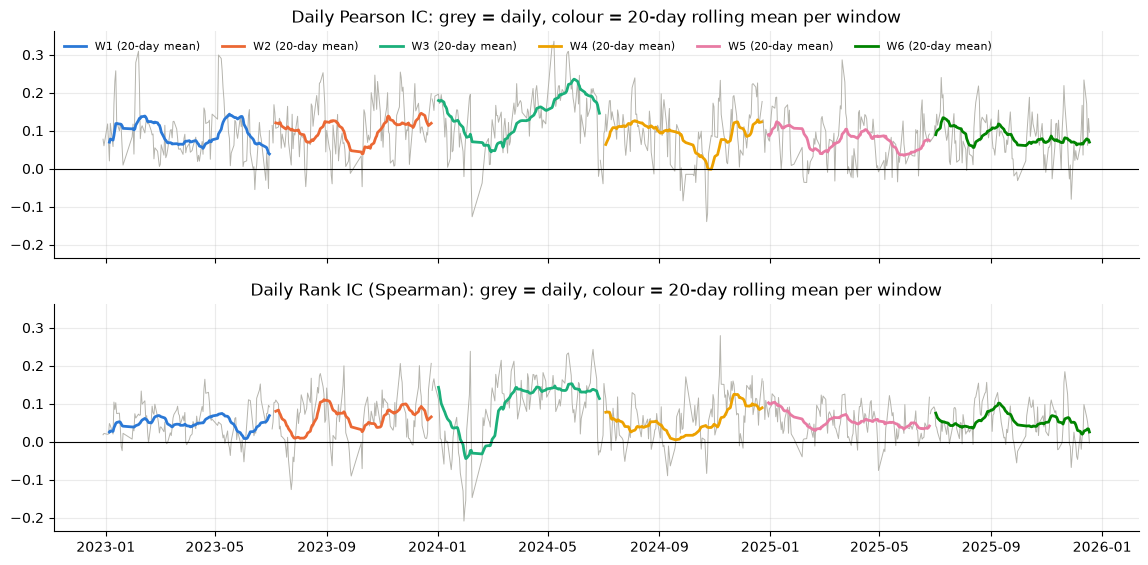

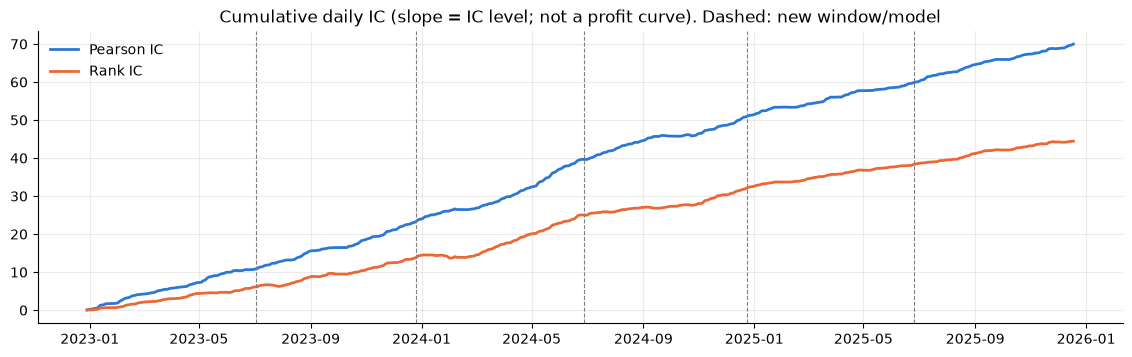

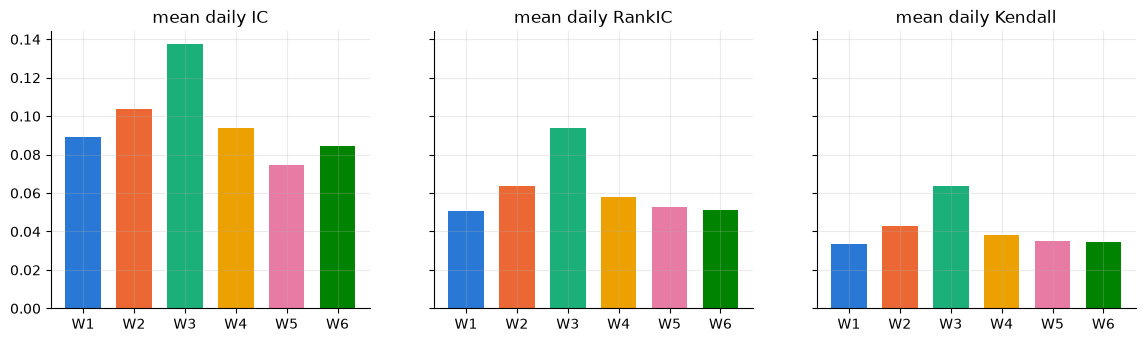

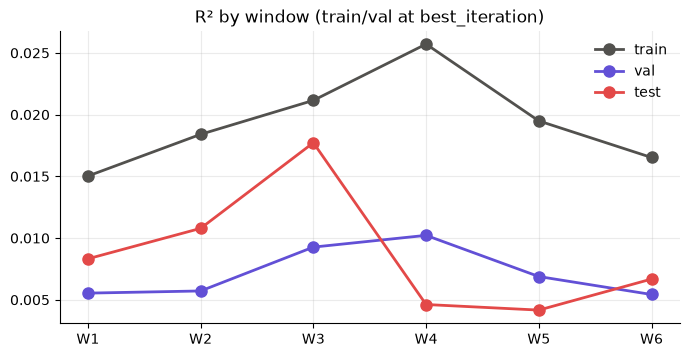

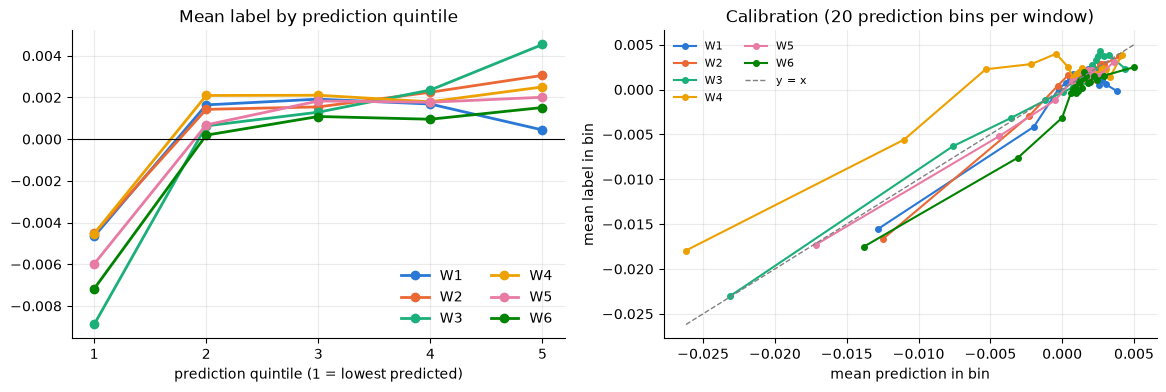

shape: (6, 6)
┌────────┬───────────┬──────────┬──────────┬──────────┬──────────┐
│ window ┆ 1         ┆ 2        ┆ 3        ┆ 4        ┆ 5        │
│ ---    ┆ ---       ┆ ---      ┆ ---      ┆ ---      ┆ ---      │
│ i32    ┆ f32       ┆ f32      ┆ f32      ┆ f32      ┆ f32      │
╞════════╪═══════════╪══════════╪══════════╪══════════╪══════════╡
│ 1      ┆ -0.004664 ┆ 0.001641 ┆ 0.001917 ┆ 0.001681 ┆ 0.00044  │
│ 2      ┆ -0.004525 ┆ 0.001427 ┆ 0.001545 ┆ 0.002248 ┆ 0.003056 │
│ 3      ┆ -0.008889 ┆ 0.000636 ┆ 0.001291 ┆ 0.002355 ┆ 0.004537 │
│ 4      ┆ -0.004532 ┆ 0.002093 ┆ 0.002104 ┆ 0.001791 ┆ 0.002502 │
│ 5      ┆ -0.005987 ┆ 0.000682 ┆ 0.001828 ┆ 0.001769 ┆ 0.002008 │
│ 6      ┆ -0.007176 ┆ 0.000191 ┆ 0.001085 ┆ 0.000954 ┆ 0.001516 │
└────────┴───────────┴──────────┴──────────┴──────────┴──────────┘


In [5]:
fig, axes = plt.subplots(2, 1, figsize=(14, 6.5), sharex=True, sharey=True)
for ax, col, name in zip(axes, ["ic", "rank_ic"], ["Pearson IC", "Rank IC (Spearman)"]):
    for w in range(1, n_windows + 1):
        d = daily.filter(pl.col("window") == w)
        x = d["Date"].to_numpy()
        ax.plot(x, d[col], color="#b5b4ad", lw=0.7)
        ax.plot(x, d[col].rolling_mean(20, min_samples=5),
                color=WINDOW_COLORS[w - 1], label=f"W{w} (20-day mean)")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(f"Daily {name}: grey = daily, colour = 20-day rolling mean per window")
axes[0].legend(ncol=n_windows, loc="upper left", fontsize=8)
save(fig, "ic_over_time")

fig, ax = plt.subplots(figsize=(14, 3.8))
x = daily["Date"].to_numpy()
ax.plot(x, daily["ic"].fill_nan(0).cum_sum(), color=WINDOW_COLORS[0], label="Pearson IC")
ax.plot(x, daily["rank_ic"].fill_nan(0).cum_sum(), color=WINDOW_COLORS[1], label="Rank IC")
for w in range(2, n_windows + 1):
    ax.axvline(daily.filter(pl.col("window") == w)["Date"][0], color="gray", ls="--", lw=0.8)
ax.set_title("Cumulative daily IC (slope = IC level; not a profit curve). Dashed: new window/model")
ax.legend()
save(fig, "cumulative_ic")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
wins = summary["window"].to_list()
for ax, col in zip(axes, ["IC", "RankIC", "Kendall(daily)"]):
    ax.bar(wins, summary[col], color=WINDOW_COLORS[:n_windows], width=0.7)
    ax.set_title(f"mean daily {col.replace('(daily)', '')}")
    ax.set_xticks(wins, [f"W{w}" for w in wins])
save(fig, "metrics_by_window")

fig, ax = plt.subplots(figsize=(8, 3.8))
for split, col in [("train", "train R2"), ("val", "val R2"), ("test", "test R2")]:
    ax.plot(wins, summary[col], "o-", color=SPLIT_COLORS[split], label=split, ms=8)
ax.set_xticks(wins, [f"W{w}" for w in wins])
ax.set_title("R² by window (train/val at best_iteration)")
ax.legend()
save(fig, "r2_by_window")

quint = (
    quint_daily.group_by(["window", "quintile"]).agg(pl.col("label_mean").mean())
    .sort(["window", "quintile"])
)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for w in range(1, n_windows + 1):
    q = quint.filter(pl.col("window") == w)
    axes[0].plot(q["quintile"], q["label_mean"], "o-", color=WINDOW_COLORS[w - 1], label=f"W{w}", ms=6)
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set_xticks([1, 2, 3, 4, 5])
axes[0].set_xlabel("prediction quintile (1 = lowest predicted)")
axes[0].set_title("Mean label by prediction quintile")
axes[0].legend(ncol=2)
binned = (
    preds.with_columns(
        ((pl.col("Prediction").rank("ordinal").over("window").cast(pl.Int64) - 1) * 20
         // pl.len().over("window")).alias("bin")
    )
    .group_by(["window", "bin"]).agg(pl.col("Prediction").mean(), pl.col("label").mean())
    .sort(["window", "bin"])
)
for w in range(1, n_windows + 1):
    b = binned.filter(pl.col("window") == w)
    axes[1].plot(b["Prediction"], b["label"], "o-", color=WINDOW_COLORS[w - 1], label=f"W{w}", ms=4, lw=1.5)
lim = [binned["Prediction"].min(), binned["Prediction"].max()]
axes[1].plot(lim, lim, "--", color="gray", lw=1, label="y = x")
axes[1].set_xlabel("mean prediction in bin")
axes[1].set_ylabel("mean label in bin")
axes[1].set_title("Calibration (20 prediction bins per window)")
axes[1].legend(ncol=2, fontsize=8)
save(fig, "quintiles_calibration")
print(quint.pivot(on="quintile", index="window", values="label_mean"))


## 4. Finer grain: months and robust summaries

A weak window can mean broad weakness, or a few bad stretches inside an
otherwise good period. This section separates the two.

**How to read it.** A single month (~20 test days, with strongly
autocorrelated daily ICs) is worth only ~5 independent days. One bad month
proves little; look for **patterns**: months that are bad across several
models, or runs of weak months. Headline metrics stay full-period. Months are
never excluded after the fact (that would be cherry-picking).

- **Top panel:** monthly mean daily **Rank IC** (bars, colour = window) and
  **Pearson IC** (black dots). Dots far above their bar mark months where the
  signal worked only through a few extreme stocks.
- **Bottom panel:** monthly **calibration slope**, the regression slope of
  label on prediction. 1 means magnitudes are right; below 1 means
  overconfident (predictions too spread out); below 0.5 (dotted) means
  strongly overconfident.
- **Robust table:** median daily IC and a 10%-trimmed mean. If they are close
  to the mean, the window's result isn't driven by a few extreme days.


window,month,days,IC,RankIC,IC>0 %,R2,slope
i32,str,u32,f64,f64,f64,f64,f64
1,"""2022-12""",2,0.069,0.020,100.000,0.003,0.866
1,"""2023-01""",16,0.110,0.041,100.000,0.010,1.429
1,"""2023-02""",20,0.116,0.069,100.000,0.015,1.465
1,"""2023-03""",23,0.066,0.041,100.000,0.004,0.990
1,"""2023-04""",19,0.077,0.071,100.000,0.006,1.188
1,"""2023-05""",20,0.137,0.017,100.000,0.016,1.726
1,"""2023-06""",20,0.039,0.069,80.000,-0.000,0.480
2,"""2023-07""",21,0.102,0.013,100.000,0.010,1.150
2,"""2023-08""",23,0.115,0.103,86.957,0.013,1.524


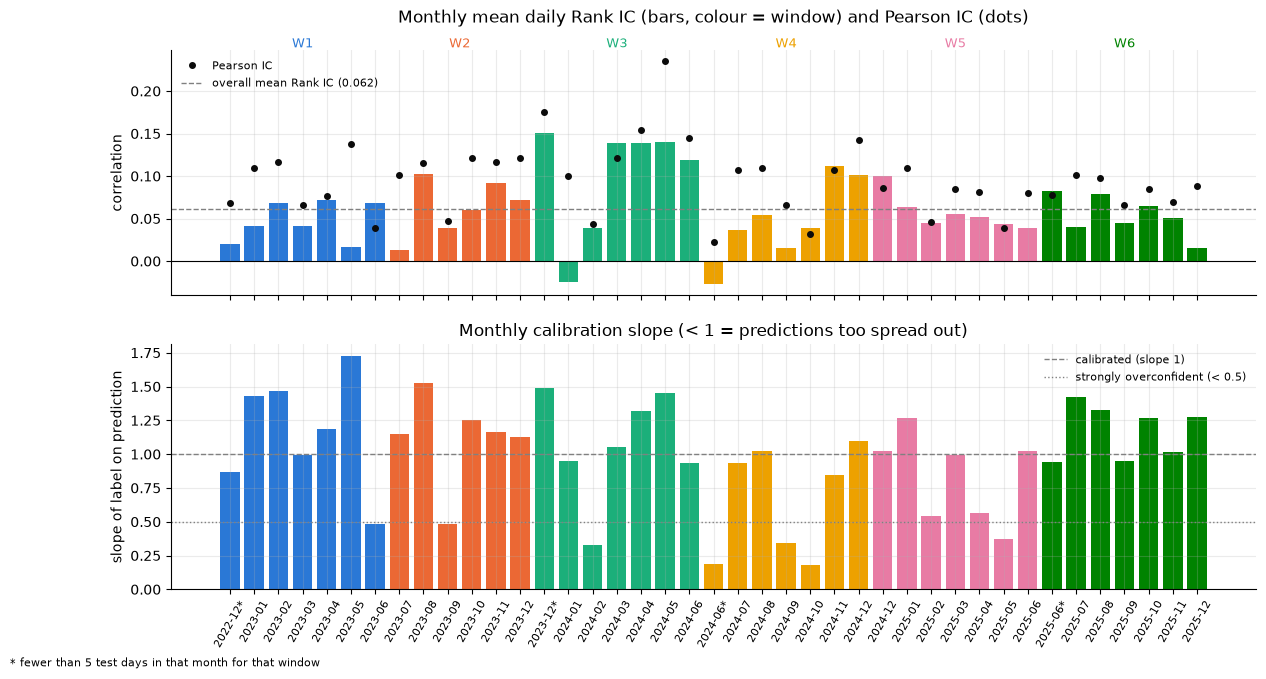

window,IC mean,IC median,IC trimmed 10%,RankIC median,RankIC>0 %
i32,f64,f64,f64,f64,f64
1,0.0894,0.0832,0.0828,0.0485,87.5000
2,0.1036,0.0964,0.1028,0.0701,84.1667
3,0.1373,0.1460,0.1392,0.1125,86.6667
4,0.0937,0.0975,0.0974,0.0561,82.5000
5,0.0746,0.0749,0.0736,0.0485,92.5000
6,0.0846,0.0805,0.0834,0.0494,84.1667


In [6]:
def month_stats(frame: pl.DataFrame, by: list[str]) -> pl.DataFrame:
    """Pooled R² and calibration slope per group of rows."""
    return frame.group_by(by).agg(
        (1 - ((pl.col("label") - pl.col("Prediction")) ** 2).sum()
         / ((pl.col("label") - pl.col("label").mean()) ** 2).sum()).alias("R2"),
        (pl.cov("Prediction", "label") / pl.col("Prediction").var()).alias("slope"),
    )


preds = preds.with_columns(pl.col("Date").dt.strftime("%Y-%m").alias("month"))
daily = daily.with_columns(pl.col("Date").dt.strftime("%Y-%m").alias("month"))
monthly = (
    daily.group_by(["window", "month"]).agg(
        pl.len().alias("days"),
        pl.col("ic").mean().alias("IC"),
        pl.col("rank_ic").mean().alias("RankIC"),
        (100 * (pl.col("ic") > 0).mean()).alias("IC>0 %"),
    )
    .join(month_stats(preds, ["window", "month"]), on=["window", "month"])
    .sort(["month", "window"])
)
with pl.Config(tbl_rows=-1, float_precision=3):
    display(monthly)  # noqa: F821

x = np.arange(monthly.height)
colors = [WINDOW_COLORS[w - 1] for w in monthly["window"]]
labels_x = [m if d >= 5 else f"{m}*" for m, d in zip(monthly["month"], monthly["days"])]
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].bar(x, monthly["RankIC"], color=colors, width=0.8)
axes[0].plot(x, monthly["IC"], "o", color="#0b0b0b", ms=4, label="Pearson IC")
axes[0].axhline(0, color="black", lw=0.8)
axes[0].axhline(daily["rank_ic"].mean(), color="gray", ls="--", lw=1,
                label=f"overall mean Rank IC ({daily['rank_ic'].mean():.3f})")
axes[0].set_ylabel("correlation")
axes[0].set_title("Monthly mean daily Rank IC (bars, colour = window) and Pearson IC (dots)", pad=20)
axes[0].legend(loc="upper left", fontsize=8)
axes[1].bar(x, monthly["slope"], color=colors, width=0.8)
axes[1].axhline(1, color="gray", ls="--", lw=1, label="calibrated (slope 1)")
axes[1].axhline(0.5, color="gray", ls=":", lw=1, label="strongly overconfident (< 0.5)")
axes[1].set_ylabel("slope of label on prediction")
axes[1].set_title("Monthly calibration slope (< 1 = predictions too spread out)")
axes[1].legend(loc="upper right", fontsize=8)
axes[1].set_xticks(x, labels_x, rotation=60, fontsize=8)
# Window labels above the top panel.
for w in range(1, n_windows + 1):
    idx = np.flatnonzero(monthly["window"].to_numpy() == w)
    axes[0].annotate(f"W{w}", (idx.mean(), 1.0), xycoords=("data", "axes fraction"),
                     ha="center", va="bottom", fontsize=9, color=WINDOW_COLORS[w - 1])
fig.text(0.01, 0.0, "* fewer than 5 test days in that month for that window", fontsize=8)
save(fig, "monthly")

robust = daily.group_by("window").agg(
    pl.col("ic").mean().alias("IC mean"),
    pl.col("ic").median().alias("IC median"),
    pl.col("ic").filter(
        pl.col("ic").is_between(pl.col("ic").quantile(0.1), pl.col("ic").quantile(0.9))
    ).mean().alias("IC trimmed 10%"),
    pl.col("rank_ic").median().alias("RankIC median"),
    (100 * (pl.col("rank_ic") > 0).mean()).alias("RankIC>0 %"),
).sort("window")
with pl.Config(float_precision=4):
    display(robust)  # noqa: F821


## 5. Ex-ante regimes: does performance depend on observable conditions?

**What a regime split is.** Each test day is put into a group ("regime")
according to the market conditions on that day, and performance is compared
across groups.

**Why ex-ante (known in advance).** A regime split is only useful if you could
have *acted* on it: trust or size the signal more in some conditions, add the
condition as a model feature, or check whether a model variant (e.g. history
features) helps mainly in certain conditions. So each day's regime is built
**only from information available at the close of day T**. Labelling months
after the fact ("that was a crash month") can explain the past, but nobody
could have traded on it, and it invites cherry-picking. A regime split does
**not** try to foresee shocks. Finding that the regime *can't* flag the bad
periods is itself a useful (negative) result.

**How the regime is built.**
1. *Dispersion* = the cross-sectional std of the label on a date: how
   differently stocks moved. Labels are factor-adjusted, so this is
   stock-specific dispersion, **not** market volatility.
2. *Trailing dispersion* at T = the mean dispersion over dates T−26 … T−7.
   Those labels are fully realized by day T, so there is no look-ahead.
3. *Percentile* = where today's trailing dispersion ranks among the previous
   ~250 trading days (one year, at least 120 needed). Below the 33rd
   percentile is **calm**, above the 67th is **turbulent**, and in between is
   **normal**. Relative to the past year, so the thresholds adapt over time.

**How to read the charts.**
- *Timeline* (three rows sharing the date axis):
  1. Daily dispersion (thin) and the trailing measure (bold). Dotted lines
     mark the largest dispersion spikes. Note how the trailing measure reacts
     only after a spike: shock onsets look calm ex-ante.
  2. The percentile and the 1/3 and 2/3 thresholds. Background shading =
     regime (light = calm, dark = turbulent), the same in all rows.
  3. Daily Rank IC (faint) and its 20-day mean (bold), against the regime
     shading.
- *Summary*: left, mean daily Rank IC per regime, with Newey–West 95%
  confidence intervals and the number of days and of distinct **episodes**
  (separate runs of ≥ 5 days). Few episodes means weak evidence, however many
  days they cover. Right, the same per window: if the effect is real it
  should appear in most windows, not just one.

**In the comparison (section 6)** the same regimes are used to check *where*
a variant helps: e.g. whether history features mainly help after dispersion
spikes.


In [7]:
LAG, SPAN, HISTORY, MIN_HISTORY = 7, 20, 250, 120
per_day = (
    pl.read_parquet(DATA_FILE, columns=["Date", "label"]).drop_nulls()
    .group_by("Date").agg(pl.col("label").std().alias("std"))
    .sort("Date")
)
REGIMES = ["calm", "normal", "turbulent"]
REGIME_COLORS = {"calm": "#cde2fb", "normal": "#6da7ec", "turbulent": "#184f95"}

per_day = per_day.sort("Date").with_columns(
    pl.col("std").shift(LAG).rolling_mean(SPAN).alias("trail_disp")   # dates T-26 ... T-7
)
td = per_day["trail_disp"].fill_null(np.nan).to_numpy()
pct = np.full(len(td), np.nan)
for i in range(len(td)):
    past = td[max(0, i - HISTORY):i]
    past = past[~np.isnan(past)]
    if len(past) >= MIN_HISTORY and not np.isnan(td[i]):
        pct[i] = (past < td[i]).mean()      # percentile vs the previous ~1 year
per_day = per_day.with_columns(pl.Series("disp_pct", pct).fill_nan(None)).with_columns(
    pl.when(pl.col("disp_pct").is_null()).then(None)
    .when(pl.col("disp_pct") < 1 / 3).then(pl.lit("calm"))
    .when(pl.col("disp_pct") < 2 / 3).then(pl.lit("normal"))
    .otherwise(pl.lit("turbulent")).alias("regime")
)
day_regime = per_day.select("Date", "regime")
daily = daily.drop("regime", strict=False).join(day_regime, on="Date", how="left")
preds = preds.drop("regime", strict=False).join(day_regime, on="Date", how="left")
test_days = (
    daily.group_by("Date").agg(pl.col("rank_ic").mean(), pl.col("regime").first())
    .sort("Date")
)
print("test days without a regime (too little history):", test_days["regime"].null_count())


def episodes(frame: pl.DataFrame, min_len: int = 5) -> pl.DataFrame:
    """Contiguous runs of the same regime over consecutive test days."""
    runs = (
        frame.with_columns((pl.col("regime") != pl.col("regime").shift()).fill_null(True)
                           .cum_sum().alias("run"))
        .group_by("run", maintain_order=True)
        .agg(pl.col("regime").first(), pl.col("Date").first().alias("start"),
             pl.col("Date").last().alias("end"), pl.len().alias("days"))
    )
    return runs.filter(pl.col("days") >= min_len)


rows = []
eps = episodes(test_days.drop_nulls("regime"))
for r in REGIMES:
    d = daily.filter(pl.col("regime") == r)
    ric = d.sort("Date")["rank_ic"].drop_nans().to_numpy()
    rows.append({
        "regime": r, "days": d["Date"].n_unique(),
        "episodes (>=5 days)": eps.filter(pl.col("regime") == r).height,
        "RankIC": ric.mean(), "RankIC 95% CI ±": nw_ci(ric),
        "IC": d["ic"].mean(), "RankIC>0 %": 100 * (ric > 0).mean(),
        "Q5-Q1": d["q5_minus_q1"].mean(),
    })
by_regime = pl.DataFrame(rows)
by_window = (
    daily.drop_nulls("regime").group_by(["window", "regime"])
    .agg(pl.len().alias("days"), pl.col("rank_ic").mean().alias("RankIC"))
    .sort(["window", "regime"])
)
with pl.Config(float_precision=4, tbl_rows=-1):
    display(by_regime)  # noqa: F821
    display(by_window.pivot(on="regime", index="window", values=["days", "RankIC"]))  # noqa: F821


test days without a regime (too little history): 0


regime,days,episodes (>=5 days),RankIC,RankIC 95% CI ±,IC,RankIC>0 %,Q5-Q1
str,i64,i64,f64,f64,f64,f64,f64
"""calm""",283,8,0.0457,0.0123,0.0897,83.3922,0.0060
"""normal""",242,11,0.0568,0.0112,0.0860,88.0165,0.0077
"""turbulent""",195,3,0.0912,0.0181,0.1220,88.2051,0.0125


window,days_calm,days_normal,days_turbulent,RankIC_calm,RankIC_normal,RankIC_turbulent
i32,u32,u32,u32,f64,f64,f64
1,70,30,20,0.0479,0.0852,0.0083
2,99,21,null,0.0573,0.0950,null
3,28,3,89,-0.0022,0.1274,0.1229
4,7,42,71,0.0697,0.0239,0.0772
5,19,89,12,0.0422,0.0492,0.0950
6,60,57,3,0.0445,0.0601,0.0180


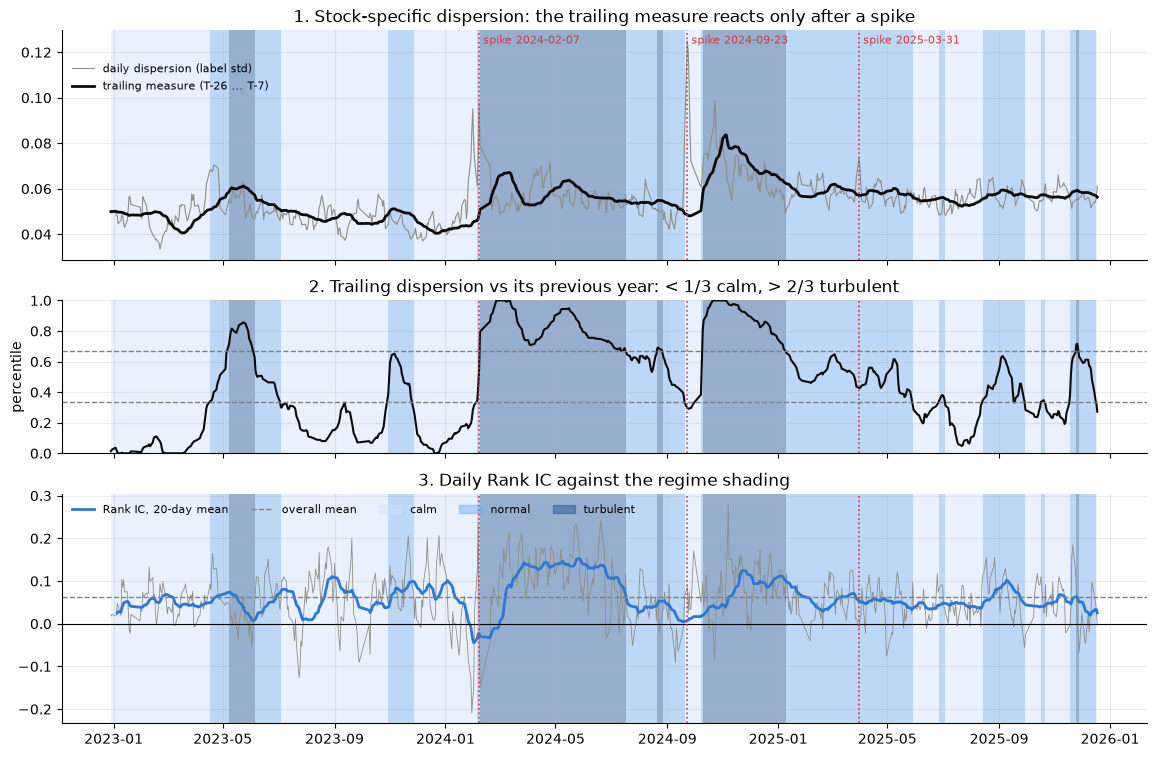

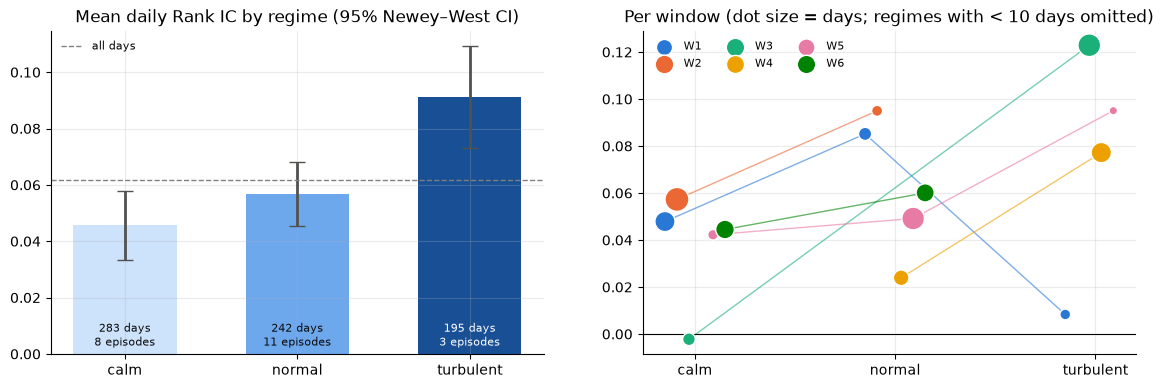

In [8]:
def shade(ax) -> None:
    """Shade the background by regime (all runs, including short ones)."""
    runs = episodes(test_days.drop_nulls("regime"), min_len=1)
    starts = runs["start"].to_list()
    ends = starts[1:] + [test_days["Date"].max()]
    for regime_name, s, e in zip(runs["regime"], starts, ends):
        ax.axvspan(s, e, color=REGIME_COLORS[regime_name], alpha=0.45, lw=0)


in_test = per_day.filter(pl.col("Date").is_between(test_days["Date"].min(), test_days["Date"].max()))
# Largest dispersion spikes in the test period, at least 60 days apart.
spikes = []
for row in in_test.sort("std", descending=True).iter_rows(named=True):
    if all(abs((row["Date"] - s).days) > 60 for s in spikes):
        spikes.append(row["Date"])
    if len(spikes) == 3:
        break

fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True,
                         gridspec_kw={"height_ratios": [1.2, 0.8, 1.2]})
dates = in_test["Date"].to_numpy()
axes[0].plot(dates, in_test["std"], color="#8f8e88", lw=0.8, label="daily dispersion (label std)")
axes[0].plot(dates, in_test["trail_disp"], color="#0b0b0b", lw=2, label="trailing measure (T-26 ... T-7)")
axes[0].set_title("1. Stock-specific dispersion: the trailing measure reacts only after a spike")
axes[1].plot(dates, in_test["disp_pct"], color="#0b0b0b", lw=1.5)
for level in (1 / 3, 2 / 3):
    axes[1].axhline(level, color="gray", ls="--", lw=1)
axes[1].set_ylim(0, 1)
axes[1].set_ylabel("percentile")
axes[1].set_title("2. Trailing dispersion vs its previous year: < 1/3 calm, > 2/3 turbulent")
t = test_days["Date"].to_numpy()
axes[2].plot(t, test_days["rank_ic"], color="#8f8e88", lw=0.6)
axes[2].plot(t, test_days["rank_ic"].rolling_mean(20, min_samples=5), color=WINDOW_COLORS[0],
             lw=2, label="Rank IC, 20-day mean")
axes[2].axhline(0, color="black", lw=0.8)
axes[2].axhline(test_days["rank_ic"].mean(), color="gray", ls="--", lw=1, label="overall mean")
axes[2].set_title("3. Daily Rank IC against the regime shading")
for ax in axes:
    shade(ax)
    for s in spikes:
        ax.axvline(s, color="#d03b3b", ls=":", lw=1.2)
for s in spikes:
    axes[0].annotate(f"spike {s}", (s, 1.0), xycoords=("data", "axes fraction"),
                     ha="left", va="top", fontsize=8, color="#d03b3b", xytext=(3, -3),
                     textcoords="offset points")
from matplotlib.patches import Patch  # noqa: E402
regime_handles = [Patch(color=REGIME_COLORS[r], alpha=0.45, label=r) for r in REGIMES]
axes[0].legend(loc="upper left", fontsize=8, bbox_to_anchor=(0, 0.9))
axes[2].legend(handles=axes[2].get_legend_handles_labels()[0] + regime_handles, loc="upper left",
               fontsize=8, ncol=5)
save(fig, "regime_timeline")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
xs = np.arange(len(REGIMES))
axes[0].bar(xs, by_regime["RankIC"], color=[REGIME_COLORS[r] for r in REGIMES], width=0.6,
            yerr=by_regime["RankIC 95% CI ±"], capsize=6, ecolor="#52514e")
axes[0].axhline(daily["rank_ic"].mean(), color="gray", ls="--", lw=1, label="all days")
for xi, row in zip(xs, by_regime.iter_rows(named=True)):
    axes[0].annotate(f"{row['days']} days\n{row['episodes (>=5 days)']} episodes", (xi, 0),
                     textcoords="offset points", xytext=(0, 6), ha="center", fontsize=8,
                     color="#0b0b0b" if row["regime"] != "turbulent" else "white")
axes[0].set_xticks(xs, REGIMES)
axes[0].set_title("Mean daily Rank IC by regime (95% Newey–West CI)")
axes[0].legend(loc="upper left", fontsize=8)
for w in range(1, n_windows + 1):
    bw = by_window.filter((pl.col("window") == w) & (pl.col("days") >= 10))
    xw = [REGIMES.index(r) + (w - (n_windows + 1) / 2) * 0.06 for r in bw["regime"]]
    axes[1].plot(xw, bw["RankIC"], "-", color=WINDOW_COLORS[w - 1], lw=1, alpha=0.6)
    axes[1].scatter(xw, bw["RankIC"], s=bw["days"] * 3, color=WINDOW_COLORS[w - 1],
                    edgecolor="white", linewidth=1, label=f"W{w}", zorder=3)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_xticks(xs, REGIMES)
axes[1].set_title("Per window (dot size = days; regimes with < 10 days omitted)")
axes[1].legend(ncol=3, fontsize=8, loc="upper left")
save(fig, "regimes")


## 6. What changed vs the baseline: purged 5-fold validation

Baseline: `run-3_baseline-chrono-val-plus-retrain`. Run: `run-4_baseline-sel-feat-purged-5-fold-val-retrain`.
Same data, windows (6), test dates (720), test universe (100% common rows),
LightGBM parameters (GOSS, MSE, 20 leaves, lr 0.01), seeds and the retrain on
all 230 history dates.

| Category | Baseline → run | Why | Expected effect |
|---|---|---|---|
| Validation protocol | One chronological block (newest 77 dates, 10-date purge) → **purged 5-fold**: 5 contiguous blocks of 46 dates, 10-date purge on each side, all folds boosted together | One block = one market period; tree counts were unstable (N-14, N-15) | Stable tree counts, so a stable prediction scale |
| Validation protocol | Early stopping on one block's RMSE → on the **fold-mean validation R²** (patience 200) | Each period weighs the same | As above |
| Features | Selected once on the 143 training dates → selected **per fold** on that fold's training dates; the final set re-selected on all 230 dates | No validation labels in the selection; the final set uses all history | Honest validation curves; the final set uses more data |

**Effective consequences:**
- Tree counts 209, 1487, 278, 708, 59, 116 → 411, 453, 334, 402, 273, 350.
- Final feature counts 36, 34, 42, 37, 40, 33 → 34, 40, 40, 40, 34, 33.
- Runtime 188 s → 603 s (×3.2). Peak memory unchanged (1.5–2.1 GB).

The protocol and the feature set changed together. Given N-15, the tree
count is expected to dominate.


In [9]:
assert COMPARE, "No baseline set: skip this section."
import difflib  # noqa: E402
import io  # noqa: E402
import tokenize  # noqa: E402


def code_without_comments(path: Path) -> list[str]:
    """Source lines with comments and blank lines removed (NOTE comments aren't setup changes)."""
    out, last_line = [], -1
    tokens = tokenize.generate_tokens(io.StringIO(path.read_text(encoding="utf-8")).readline)
    kept = [t for t in tokens if t.type != tokenize.COMMENT]
    src = tokenize.untokenize(kept)
    for line in src.splitlines():
        if line.strip():
            out.append(line.rstrip())
    return out


def archived_script(run_dir: Path) -> Path | None:
    """The training script copy archived in the run folder (largest .py, if several)."""
    scripts = [p for p in run_dir.glob("*.py")]
    return max(scripts, key=lambda p: p.stat().st_size) if scripts else None


run_script, base_script = archived_script(RUN_DIR), archived_script(BASELINE_DIR)
print(f"run script:      {run_script.name if run_script else 'NOT ARCHIVED'}")
print(f"baseline script: {base_script.name if base_script else 'NOT ARCHIVED'}")
if run_script and base_script:
    diff = list(difflib.unified_diff(code_without_comments(base_script), code_without_comments(run_script),
                                     fromfile=f"baseline/{base_script.name}", tofile=f"run/{run_script.name}",
                                     n=1, lineterm=""))
    print(f"\n--- code diff (comments and blank lines ignored): {sum(l.startswith(('+', '-')) and not l.startswith(('+++', '---')) for l in diff)} changed lines ---")
    print("\n".join(diff) if diff else "(no code differences)")

# Per-window data and selection facts, matched by test start date.
b_by_start = {r["test_start"]: r for r in b_results}
rows = []
for k, r in enumerate(results):
    b = b_by_start.get(r["test_start"], {})
    rows.append({"window": k + 1, "test_start": r["test_start"]}
                | {f"{key} base": b.get(key) for key in ("train_rows", "validation_rows", "test_rows", "features")}
                | {f"{key} run": r.get(key) for key in ("train_rows", "validation_rows", "test_rows", "features")})
setup_facts = pl.DataFrame(rows)
with pl.Config(tbl_rows=-1, tbl_cols=-1, tbl_width_chars=250):
    display(setup_facts)  # noqa: F821


def selected_features(run_dir: Path) -> dict[str, set[str]]:
    """Selected features per window (keyed by test start), from models/*.features.json."""
    out = {}
    for f in (run_dir / "models").glob("*.features.json"):
        m = re.search(r"_test_(\d{4}-\d{2}-\d{2})_", f.name)
        if m:
            out[m[1]] = set(json.loads(f.read_text())["features"])
    return out


run_feats, base_feats = selected_features(RUN_DIR), selected_features(BASELINE_DIR)
for k, r in enumerate(results):
    a, b = run_feats.get(r["test_start"]), base_feats.get(r["test_start"])
    if a is None or b is None:
        print(f"W{k + 1}: feature lists not available")
        continue
    print(f"W{k + 1}: {len(b)} -> {len(a)} features; added {sorted(a - b) or '-'}; removed {sorted(b - a) or '-'}")


run script:      train_baseline-sel-feat-purged-5-fold-val-retrain.py
baseline script: train_baseline-chrono-val-plus-retrain.py

--- code diff (comments and blank lines ignored): 381 changed lines ---
--- baseline/train_baseline-chrono-val-plus-retrain.py
+++ run/train_baseline-sel-feat-purged-5-fold-val-retrain.py
@@ -4,2 +4,3 @@
 import gc
+import itertools
 import json
@@ -10,2 +11,3 @@
 import time
+from dataclasses import dataclass
 from pathlib import Path
@@ -21,3 +23,3 @@
 DATA_FILE = ROOT / "data.parquet"
-RUN_DIR = ROOT / "runs/run-3_baseline-chrono-val-plus-retrain"
+RUN_DIR = ROOT / "runs/run-4_baseline-sel-feat-purged-5-fold-val-retrain"
 RESULT_FILE = RUN_DIR / "results_lgbm.json"
@@ -26,5 +28,5 @@
 CURVES_DIR = RUN_DIR / "curves"
-ARXIV_FILE = RUN_DIR / "train_baseline-chrono-val-plus-retrain.py"
-CURVE_FLUSH_EVERY = 50
-PLOT_REFRESH_SECONDS = 5
+ARXIV_FILE = RUN_DIR / "train_baseline-sel-feat-purged-5-fold-val-retrain.py"
+CURVE_FLUSH_EVERY = 10
+PLOT_REFRESH_SECONDS =

window,test_start,train_rows base,validation_rows base,test_rows base,features base,train_rows run,validation_rows run,test_rows run,features run
i64,str,i64,i64,i64,i64,i64,i64,i64,i64
1,"""2022-12-29""",366410,206756,328789,36,437644,119909,328789,34
2,"""2023-07-03""",383427,211216,336828,34,454199,124389,336828,40
3,"""2023-12-26""",392672,216757,339720,42,465560,127475,339720,40
4,"""2024-06-28""",401930,218028,339196,37,473444,129662,339196,40
5,"""2024-12-24""",404656,217665,341037,40,475201,130113,341037,34
6,"""2025-06-26""",404421,218819,343247,33,476001,130339,343247,33


W1: 36 -> 34 features; added -; removed ['feature16', 'feature24']
W2: 34 -> 40 features; added ['feature16', 'feature24', 'feature26', 'feature4', 'feature41', 'feature47']; removed -
W3: 42 -> 40 features; added -; removed ['feature36', 'feature4']
W4: 37 -> 40 features; added ['feature16', 'feature24', 'feature4', 'feature40', 'feature41', 'feature47']; removed ['feature2', 'feature29', 'feature7']
W5: 40 -> 34 features; added ['feature18']; removed ['feature10', 'feature3', 'feature36', 'feature4', 'feature41', 'feature42', 'feature47']
W6: 33 -> 33 features; added ['feature19']; removed ['feature7']


## 7. Comparison with the baseline: `run-3_baseline-chrono-val-plus-retrain`

**Is the run better than the baseline, and where?** Market conditions move
every model's IC far more than model changes do: whole windows rise and fall
together. So the two models are compared **paired**: on the **same (Date,
Code) rows**, day by day.

- **Coverage:** only rows present in both runs are compared. If the run
  changes the universe (e.g. drops new listings), the comparison is
  restricted to the common rows; the run's own section 1–5 metrics still use
  all of its rows.
- **Daily delta** = run − baseline for Rank IC, IC and Q5−Q1 on each date.
  Its mean is the improvement, with a **Newey–West 95% CI** (deltas are
  autocorrelated too). **% days better** = share of dates where the run's
  Rank IC is higher.
- **Where:** the delta per window, per month and per ex-ante regime. A real
  improvement should be positive in **most windows**, not carried by one.
- **Agreement:** the daily rank correlation between the two models'
  predictions. Near 1 means the run barely changed what the model believes.
- **Magnitudes** (as important as ranking: the predictions feed a portfolio
  optimizer): calibration slope, R² and RMSE per window on the common rows,
  and quintile profiles, for both models.

Rules of thumb: an improvement of ~+0.005 Rank IC is meaningful **if** its CI
excludes 0 and it holds in most windows. Never choose a variant using the
final reserved window.


In [10]:
assert COMPARE, "No baseline set: skip this section."

# ---- Align the two runs on common (Date, Code) rows -----------------------------
pair = (
    preds.select("window", "Date", "Code", "label", pl.col("Prediction").alias("p_run"))
    .join(b_preds.select("Date", "Code", pl.col("label").alias("label_base"),
                         pl.col("Prediction").alias("p_base")),
          on=["Date", "Code"], how="inner")
)
label_mismatch = pair.filter((pl.col("label") - pl.col("label_base")).abs() > 1e-6).height
print(f"rows: run {preds.height:,} | baseline {b_preds.height:,} | common {pair.height:,} "
      f"({100 * pair.height / preds.height:.1f}% of run) on {pair['Date'].n_unique()} dates; "
      f"label mismatches: {label_mismatch}")
assert pair.height > 0, "no common rows"
if label_mismatch:
    print("  WARNING: labels differ between runs on some rows (transformed labels?). "
          "The comparison uses the run's labels.")

# ---- Paired daily metrics ------------------------------------------------------------
quint_expr = [
    ((pl.col(p).rank("ordinal").over("Date").cast(pl.Int64) - 1) * 5 // pl.len().over("Date") + 1)
    .alias(f"q_{p[2:]}") for p in ("p_run", "p_base")
]
pair = pair.with_columns(quint_expr)


def q_mean(q_col: str, q: int) -> pl.Expr:
    return pl.col("label").filter(pl.col(q_col) == q).mean()


paired = (
    pair.group_by(["window", "Date"])
    .agg(
        pl.corr("p_run", "label", method="spearman").alias("ric_run"),
        pl.corr("p_base", "label", method="spearman").alias("ric_base"),
        pl.corr("p_run", "label").alias("ic_run"),
        pl.corr("p_base", "label").alias("ic_base"),
        (q_mean("q_run", 5) - q_mean("q_run", 1)).alias("spread_run"),
        (q_mean("q_base", 5) - q_mean("q_base", 1)).alias("spread_base"),
        q_mean("q_run", 1).alias("q1_run"), q_mean("q_base", 1).alias("q1_base"),
        q_mean("q_run", 5).alias("q5_run"), q_mean("q_base", 5).alias("q5_base"),
        pl.corr("p_run", "p_base", method="spearman").alias("pred_agreement"),
    )
    .with_columns(
        (pl.col("ric_run") - pl.col("ric_base")).alias("d_ric"),
        (pl.col("ic_run") - pl.col("ic_base")).alias("d_ic"),
        (pl.col("spread_run") - pl.col("spread_base")).alias("d_spread"),
        pl.col("Date").dt.strftime("%Y-%m").alias("month"),
    )
    .join(day_regime, on="Date", how="left")
    .sort("Date")
)


def delta_row(d: pl.DataFrame, **label) -> dict:
    """Summary of paired daily deltas for one slice of dates."""
    x = d.sort("Date")["d_ric"].drop_nans().to_numpy()
    return {
        **label,
        "days": d.height,
        "RankIC base": d["ric_base"].mean(),
        "RankIC run": d["ric_run"].mean(),
        "dRankIC": x.mean(),
        "95% CI ±": nw_ci(x) if len(x) > 10 else float("nan"),
        "t(NW)": newey_west_t(x) if len(x) > 10 else float("nan"),
        "run better %": 100 * (x > 0).mean(),
        "dIC": d["d_ic"].mean(),
        "dQ5-Q1": d["d_spread"].mean(),
        "Q1 base": d["q1_base"].mean(), "Q1 run": d["q1_run"].mean(),
        "Q5 base": d["q5_base"].mean(), "Q5 run": d["q5_run"].mean(),
        "agreement": d["pred_agreement"].mean(),
    }


overall = delta_row(paired, scope="all")
by_window_delta = pl.DataFrame(
    [delta_row(paired.filter(pl.col("window") == w), scope=f"W{w}")
     for w in sorted(paired["window"].unique())]
)
by_month_delta = (
    paired.group_by("month").agg(
        pl.len().alias("days"), pl.col("d_ric").mean().alias("dRankIC"),
        pl.col("ric_base").mean().alias("RankIC base"), pl.col("ric_run").mean().alias("RankIC run"),
        (100 * (pl.col("d_ric") > 0).mean()).alias("run better %"),
    ).sort("month")
)
by_regime_delta = pl.DataFrame(
    [delta_row(paired.filter(pl.col("regime") == r), scope=r) for r in REGIMES
     if paired.filter(pl.col("regime") == r).height]
)

# ---- Calibration and per-window facts for both models ---------------------------
def slope(frame: pl.DataFrame, p: str) -> pl.Expr:
    return (pl.cov(p, "label") / pl.col(p).var()).alias(f"slope_{p[2:]}")


def r2(p: str) -> pl.Expr:
    return (1 - ((pl.col("label") - pl.col(p)) ** 2).sum()
            / ((pl.col("label") - pl.col("label").mean()) ** 2).sum()).alias(f"R2_{p[2:]}")


def rmse(p: str) -> pl.Expr:
    return ((pl.col("label") - pl.col(p)) ** 2).mean().sqrt().alias(f"RMSE_{p[2:]}")


magnitude_exprs = [slope(pair, "p_base"), slope(pair, "p_run"), r2("p_base"), r2("p_run"),
                   rmse("p_base"), rmse("p_run")]
calib = pair.group_by("window").agg(magnitude_exprs).sort("window")
magnitude_all = pair.select(magnitude_exprs)
b_by_start = {r["test_start"]: r for r in b_results}
facts = pl.DataFrame([{
    "window": k + 1,
    "best_iter base": b_by_start.get(r["test_start"], {}).get("best_iteration"),
    "best_iter run": r.get("best_iteration"),
    "features base": b_by_start.get(r["test_start"], {}).get("features"),
    "features run": r.get("features"),
    "test R2 base": b_by_start.get(r["test_start"], {}).get("r2"),
    "test R2 run": r.get("r2"),
    "runtime base": b_by_start.get(r["test_start"], {}).get("runtime"),
    "runtime run": r.get("runtime"),
} for k, r in enumerate(results)]).join(calib, on="window", how="left")

print(f"\nOVERALL: Rank IC {overall['RankIC base']:.4f} -> {overall['RankIC run']:.4f}  "
      f"dRankIC {overall['dRankIC']:+.4f} ± {overall['95% CI ±']:.4f} (t NW {overall['t(NW)']:.1f}), "
      f"run better on {overall['run better %']:.0f}% of days; dIC {overall['dIC']:+.4f}; "
      f"dQ5-Q1 {overall['dQ5-Q1']:+.4f}; prediction agreement {overall['agreement']:.2f}")
m = magnitude_all.row(0, named=True)
print(f"MAGNITUDES (common rows): calibration slope {m['slope_base']:.3f} -> {m['slope_run']:.3f}; "
      f"R2 {m['R2_base']:.4f} -> {m['R2_run']:.4f}; RMSE {m['RMSE_base']:.5f} -> {m['RMSE_run']:.5f}")
n_pos = (by_window_delta["dRankIC"] > 0).sum()
print(f"windows with dRankIC > 0: {n_pos} of {by_window_delta.height}")
with pl.Config(tbl_rows=-1, tbl_cols=-1, float_precision=4, tbl_width_chars=250):
    display(by_window_delta)  # noqa: F821
    display(by_regime_delta)  # noqa: F821
    display(by_month_delta)  # noqa: F821
    display(facts)  # noqa: F821


rows: run 2,028,817 | baseline 2,028,817 | common 2,028,817 (100.0% of run) on 720 dates; label mismatches: 0

OVERALL: Rank IC 0.0624 -> 0.0617  dRankIC -0.0007 ± 0.0013 (t NW -1.1), run better on 50% of days; dIC +0.0011; dQ5-Q1 +0.0000; prediction agreement 0.91
MAGNITUDES (common rows): calibration slope 0.978 -> 0.927; R2 0.0080 -> 0.0085; RMSE 0.05586 -> 0.05584
windows with dRankIC > 0: 3 of 6


scope,days,RankIC base,RankIC run,dRankIC,95% CI ±,t(NW),run better %,dIC,dQ5-Q1,Q1 base,Q1 run,Q5 base,Q5 run,agreement
str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""W1""",120,0.0527,0.0506,-0.0021,0.0019,-2.1585,41.6667,-0.0009,0.0002,-0.0045,-0.0047,0.0004,0.0004,0.9606
"""W2""",120,0.0603,0.0639,0.0036,0.0033,2.1385,60.8333,0.0020,-0.0003,-0.0047,-0.0045,0.0032,0.0031,0.8776
"""W3""",120,0.0934,0.0938,0.0004,0.0008,1.0106,52.5000,0.0017,-0.0001,-0.0088,-0.0089,0.0047,0.0045,0.9804
"""W4""",120,0.0552,0.0581,0.0029,0.0017,3.2899,68.3333,-0.0029,-0.0001,-0.0047,-0.0045,0.0024,0.0025,0.9606
"""W5""",120,0.0610,0.0527,-0.0083,0.0046,-3.5792,30.0000,0.0048,0.0001,-0.0061,-0.0060,0.0017,0.0020,0.7543
"""W6""",120,0.0519,0.0512,-0.0007,0.0018,-0.7686,48.3333,0.0021,0.0003,-0.0072,-0.0072,0.0012,0.0015,0.9483


scope,days,RankIC base,RankIC run,dRankIC,95% CI ±,t(NW),run better %,dIC,dQ5-Q1,Q1 base,Q1 run,Q5 base,Q5 run,agreement
str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""calm""",283,0.0468,0.0457,-0.0011,0.0023,-0.9332,45.9364,0.0011,-0.0001,-0.0048,-0.0048,0.0012,0.0011,0.9156
"""normal""",242,0.0587,0.0568,-0.0019,0.0022,-1.6888,48.3471,0.0019,-0.0000,-0.0056,-0.0054,0.0021,0.0022,0.8740
"""turbulent""",195,0.0898,0.0912,0.0014,0.0013,2.1990,58.9744,0.0001,0.0002,-0.0083,-0.0083,0.0041,0.0042,0.9599


month,days,dRankIC,RankIC base,RankIC run,run better %
str,u32,f64,f64,f64,f64
"""2022-12""",2,0.0013,0.0186,0.0199,100.0000
"""2023-01""",16,-0.0101,0.0512,0.0411,12.5000
"""2023-02""",20,-0.0054,0.0741,0.0687,30.0000
"""2023-03""",23,-0.0002,0.0409,0.0407,39.1304
"""2023-04""",19,0.0009,0.0706,0.0715,52.6316
"""2023-05""",20,-0.0007,0.0174,0.0167,45.0000
"""2023-06""",20,0.0006,0.0679,0.0686,60.0000
"""2023-07""",21,-0.0028,0.0154,0.0126,38.0952
"""2023-08""",23,0.0029,0.1001,0.1030,52.1739


window,best_iter base,best_iter run,features base,features run,test R2 base,test R2 run,runtime base,runtime run,slope_base,slope_run,R2_base,R2_run,RMSE_base,RMSE_run
i64,i64,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
1,209,411,36,34,0.0078,0.0083,18.5188,105.3821,1.4673,1.2214,0.0078,0.0083,0.0514,0.0514
2,1487,453,34,40,0.0106,0.0108,82.2682,111.6697,1.0093,1.1279,0.0106,0.0108,0.0461,0.0461
3,278,334,42,40,0.0174,0.0177,20.9661,94.0730,1.0780,1.0566,0.0174,0.0177,0.0571,0.0571
4,708,402,37,40,0.0050,0.0046,43.6111,108.4352,0.6932,0.6960,0.0050,0.0046,0.0644,0.0644
5,59,273,40,34,0.0034,0.0042,9.5800,84.9120,1.5280,0.7606,0.0034,0.0042,0.0577,0.0577
6,116,350,33,33,0.0052,0.0067,13.3776,98.0274,1.8053,1.2097,0.0052,0.0067,0.0565,0.0564


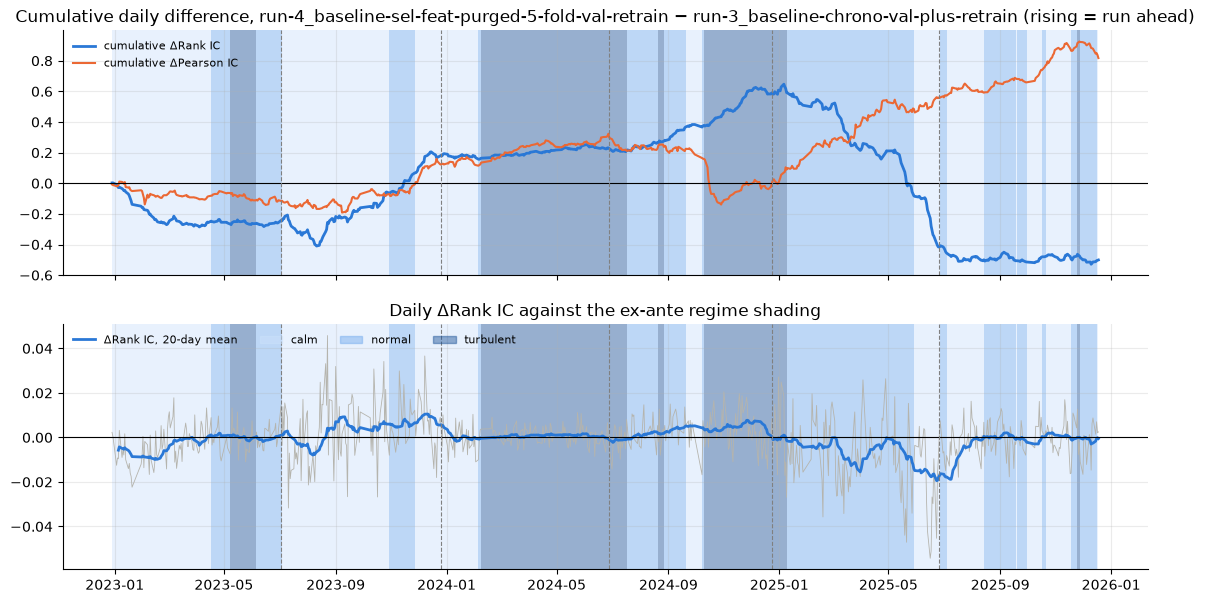

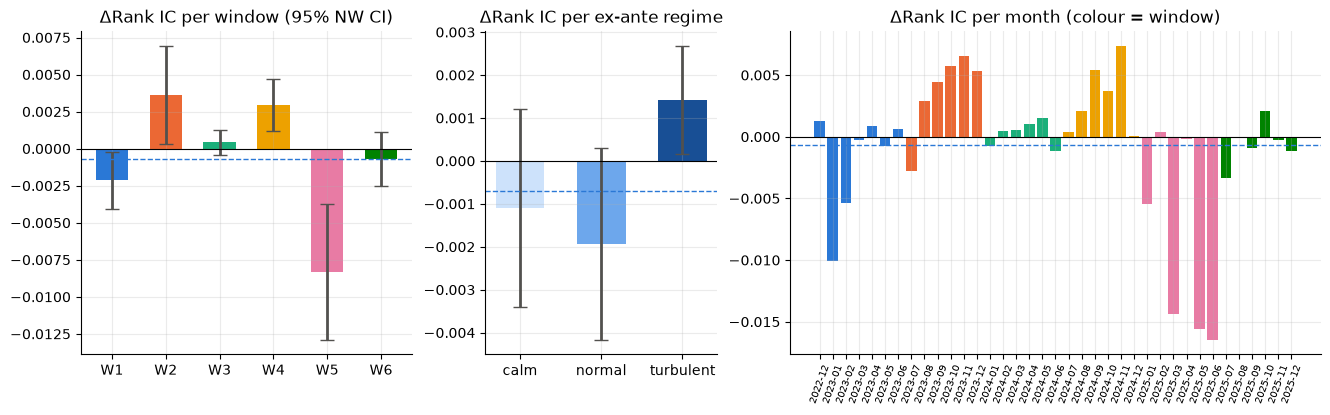

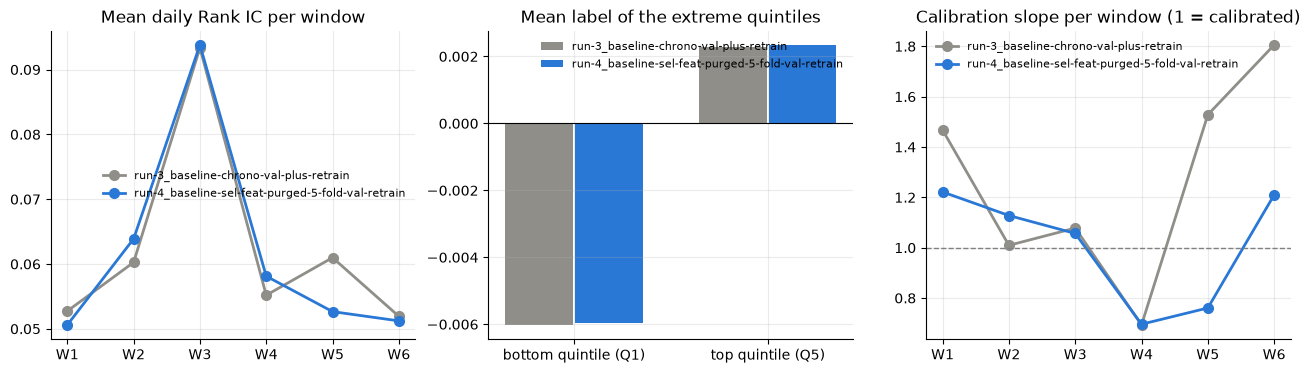

Mean daily prediction agreement (rank corr run vs baseline): 0.914


In [11]:
assert COMPARE, "No baseline set: skip this section."
run_name, base_name = RUN_DIR.name, BASELINE_DIR.name
win_starts = [paired.filter(pl.col("window") == w)["Date"].min() for w in sorted(paired["window"].unique())]

# ---- 1. Where in time does the run gain or lose? ------------------------------------
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
t = paired["Date"].to_numpy()
axes[0].plot(t, paired["d_ric"].fill_nan(0).cum_sum(), color=MODEL_COLORS["run"], label="cumulative ΔRank IC")
axes[0].plot(t, paired["d_ic"].fill_nan(0).cum_sum(), color="#eb6834", lw=1.5, label="cumulative ΔPearson IC")
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set_title(f"Cumulative daily difference, {run_name} − {base_name} (rising = run ahead)")
axes[0].legend(loc="upper left", fontsize=8)
axes[1].plot(t, paired["d_ric"], color="#b5b4ad", lw=0.6)
axes[1].plot(t, paired["d_ric"].rolling_mean(20, min_samples=5), color=MODEL_COLORS["run"],
             label="ΔRank IC, 20-day mean")
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_title("Daily ΔRank IC against the ex-ante regime shading")
for ax in axes:
    shade(ax)
    for s in win_starts[1:]:
        ax.axvline(s, color="gray", ls="--", lw=0.8)
axes[1].legend(handles=axes[1].get_legend_handles_labels()[0]
               + [Patch(color=REGIME_COLORS[r], alpha=0.45, label=r) for r in REGIMES],
               loc="upper left", fontsize=8, ncol=4)
save(fig, "compare_timeline")

# ---- 2. Is the gain consistent across windows, regimes, months? ---------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), gridspec_kw={"width_ratios": [1, 0.7, 1.6]})
wl = by_window_delta["scope"].to_list()
wcol = [WINDOW_COLORS[int(s[1:]) - 1] for s in wl]
axes[0].bar(wl, by_window_delta["dRankIC"], color=wcol, width=0.6,
            yerr=by_window_delta["95% CI ±"], capsize=5, ecolor="#52514e")
axes[0].set_title("ΔRank IC per window (95% NW CI)")
rl = by_regime_delta["scope"].to_list()
axes[1].bar(rl, by_regime_delta["dRankIC"], color=[REGIME_COLORS[r] for r in rl], width=0.6,
            yerr=by_regime_delta["95% CI ±"], capsize=5, ecolor="#52514e")
axes[1].set_title("ΔRank IC per ex-ante regime")
month_window = paired.group_by("month").agg(pl.col("window").mode().first()).sort("month")
mcol = [WINDOW_COLORS[w - 1] for w in month_window["window"]]
xm = np.arange(by_month_delta.height)
axes[2].bar(xm, by_month_delta["dRankIC"], color=mcol, width=0.8)
axes[2].set_xticks(xm, by_month_delta["month"], rotation=70, fontsize=7)
axes[2].set_title("ΔRank IC per month (colour = window)")
for ax in axes:
    ax.axhline(0, color="black", lw=0.8)
    ax.axhline(overall["dRankIC"], color=MODEL_COLORS["run"], ls="--", lw=1)
save(fig, "compare_breakdown")

# ---- 3. Levels and magnitudes for both models ----------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
xw = np.arange(len(wl))
axes[0].plot(xw, by_window_delta["RankIC base"], "o-", color=MODEL_COLORS["baseline"], label=base_name, ms=7)
axes[0].plot(xw, by_window_delta["RankIC run"], "o-", color=MODEL_COLORS["run"], label=run_name, ms=7)
axes[0].set_xticks(xw, wl)
axes[0].set_title("Mean daily Rank IC per window")
qcols = [f"Q{q}" for q in (1, 5)]
qb = [overall["Q1 base"], overall["Q5 base"]]
qr = [overall["Q1 run"], overall["Q5 run"]]
xq = np.arange(2)
axes[1].bar(xq - 0.18, qb, width=0.35, color=MODEL_COLORS["baseline"], label=base_name)
axes[1].bar(xq + 0.18, qr, width=0.35, color=MODEL_COLORS["run"], label=run_name)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_xticks(xq, ["bottom quintile (Q1)", "top quintile (Q5)"])
axes[1].set_title("Mean label of the extreme quintiles")
axes[2].plot(xw, facts["slope_base"], "o-", color=MODEL_COLORS["baseline"], label=base_name, ms=7)
axes[2].plot(xw, facts["slope_run"], "o-", color=MODEL_COLORS["run"], label=run_name, ms=7)
axes[2].axhline(1, color="gray", ls="--", lw=1)
axes[2].set_xticks(xw, [f"W{w}" for w in facts["window"]])
axes[2].set_title("Calibration slope per window (1 = calibrated)")
for ax in axes:
    ax.legend(fontsize=8)
save(fig, "compare_levels")
print(f"Mean daily prediction agreement (rank corr run vs baseline): {overall['agreement']:.3f}")


## Findings

**Run 4 on its own**

1. **Overall:** Rank IC 0.0617 (NW t 14.5), Pearson IC 0.0972 (NW t 20.7),
   ICIR 1.34, IC > 0 on 92% of days. Positive in every window (Rank IC
   0.051–0.094).
2. **Consistency:** medians and trimmed means ≈ means. Rank IC > 0 on
   82–93% of days per window.
3. **Pearson vs Rank:** Pearson ≈ 1.6× Rank IC. The edge is still in Q1
   (−0.0045 … −0.0089), with Q2–Q5 flat.
4. **Calibration:** slopes 1.22, 1.13, 1.06, 0.70, 0.76, 1.21; mean
   |slope − 1| = 0.19. W4/W5 are overconfident (hard test periods, as in
   every run).
5. **Val vs test R²:** fold-mean validation R² 0.0054–0.0102 against test
   0.0042–0.0177. Test < validation only in W4 and W5, the known hard test
   periods.
6. **Regimes:** calm 0.046 ± 0.012 (8 episodes), normal 0.057 ± 0.011 (11),
   turbulent 0.091 ± 0.018 (3 episodes). Same pattern as before.

**Comparison with run 3 (paired, 2,028,817 rows)**

7. **Ranking: no detectable difference.**
   - ΔRank IC −0.0007 ± 0.0013 (t −1.1), run better on 50% of days, 3 of 6
     windows positive. ΔPearson IC +0.0011.
   - By window: W2 +0.0036 and W4 +0.0029 (significant), W5 **−0.0083**,
     W1 −0.0021.
   - The W5 loss sits in 2025-03…06 (−0.014 … −0.017 per month). Those are
     the months where run 3's accidental 59 trees helped ranking (N-15: at
     50 trees, run 2 reached 0.0905 there).
8. **Regimes:** turbulent +0.0014 ± 0.0013 (t 2.2); calm −0.0011 and normal
   −0.0019, both with CIs including 0.
9. **Magnitudes: better.**
   - Pooled R² 0.0080 → 0.0085 (+6%); RMSE about equal.
   - R² better in 5 of 6 windows (W6 0.0052 → 0.0067); worse in W4 (0.0050
     → 0.0046).
   - Calibration is much more consistent: mean |slope − 1| 0.37 → 0.19 (run
     2: 0.18). The extreme underconfidence of run 3 (W1 1.47, W5 1.53, W6
     1.81) is gone.
10. **Agreement:** 0.91 overall; 0.75 in W5 (59 → 273 trees), ≥ 0.95 in
    W1, W3, W4 and W6.
11. **Cost:** runtime ×3.2 (603 s in total), memory the same.

**Verdict:**
- **Better, of the magnitude kind:** a consistent prediction scale and R²
  +6%, with no detectable change in ranking.
- The protocol is now robust: stable tree counts, honest validation.
- It gives up run 3's lucky few-tree ranking in W5 (−0.0083), which no
  validation rule could have chosen in advance.

**Open questions:**
- Seed noise is still unmeasured.
- Can hard periods be made less sensitive to the tree count (bagging instead
  of GOSS)?
- All features vs the filter: see run 5.


## Summary: run 4 (purged 5-fold) vs run 3

**Setup.**
- Purged 5-fold validation (stopping on the fold-mean validation R²),
  features selected per fold, retrain on all history. Everything else as in
  run 3.
- 6 windows, 720 test dates. Final window held back.

**Overall performance.**
- Ranking: Rank IC 0.0617 (Pearson 0.0972), ICIR 1.34, IC > 0 on 92% of
  days, NW t 14.5 / 20.7. Q5−Q1 0.005–0.013 (gross, label units).
- Magnitude: R² 0.0085, slopes 0.70–1.22 (mean |slope − 1| 0.19). Runtime
  603 s.

**Comparison with the baseline.**
- ΔRank IC −0.0007 ± 0.0013 (t −1.1); 3 of 6 windows; W5 −0.008, W2/W4
  +0.003.
- R² +6%, calibration error halved (0.37 → 0.19). Agreement 0.91.
- **Verdict: better (magnitude kind), ranking unchanged.**

**Where it excels.**
- Stable tree counts (273–453) and therefore a stable prediction scale.
- R² better in 5 of 6 windows.

**Where it stumbles.**
- W5 ranking, versus run 3's accidental 59 trees.
- W4/W5 are still overconfident (hard test periods).

**Probable reasons.**
1. The tree count now sits in the plateau of the fold-mean curve. That fixes
   the scale (lr 0.01 shrinkage) but cannot pick the few trees that hard
   periods prefer.
2. The test period still dominates the levels.
3. The feature-set changes play a minor role (run 5 tests them directly).

**What this run achieved and what to try next.**
- A robust, leak-free protocol.
- Next: all features (run 5), seed noise, then GOSS → bagging and label
  clipping.

**Hypotheses in brief.**
- Helped: a stable, plateau-chosen tree count (magnitudes).
- Hurt: losing the lucky small W5 tree count (ranking).
- Didn't matter: the protocol change for ranking overall.


## Hypotheses: what drove the difference vs run 3

**Likely improvements.**
1. **Stable tree count → consistent magnitudes.**
   - Mechanism: with lr 0.01, the prediction spread grows with the tree count
     (N-15). Counts of 273–453 instead of 59–1487 give a similar scale in
     every window.
   - Evidence: mean |slope − 1| 0.37 → 0.19. The largest slope fixes are in
     the windows whose tree count changed most (W5 59 → 273: 1.53 → 0.76;
     W6 116 → 350: 1.81 → 1.21). R² better in 5 of 6 windows.
   - Confidence: high.

**Likely degradations.**
1. **Losing the accidental W5 ranking gain.**
   - Mechanism: run 3's single validation block (Aug–Dec 2024) happened to
     stop at 59 trees. Few trees order the bulk better in hard periods
     (N-15).
   - Evidence: W5 ΔRank IC −0.0083 (t −3.6), concentrated in 2025-03…06.
     Agreement in W5 is 0.75, lowest of all windows.
   - Confidence: high. This was luck, not skill: no ex-ante rule picked it.
2. **Cost:** runtime ×3.2. Acceptable (~10 min per run).

**What matters most / what matters little.**
- Most: the tree count (scale), then the test period (W3 0.094 vs W1 0.051
  for every run).
- Little: the protocol's effect on ranking (ΔRank IC −0.0007, CI includes 0).
  The feature-set changes are probably small too.

**Confounding.**
- The protocol and the feature selection changed together. Their ranking
  effects can't be separated here.
- The tree-count effect can be separated: run 3's truncation check (N-15)
  already explains W5.

**Experiments to test them.**
1. Seed noise (T-4): the reference config with 2 more seeds. It would show
   whether W2 +0.0036 / W4 +0.0029 are real.
2. GOSS → bagging (T-5): if the later trees stop hurting hard periods, the
   tree count matters less, and W5-type losses should shrink.
3. Out-of-fold scale correction (T-3): should move W4/W5 slopes toward 1
   with Rank IC unchanged.
